In [29]:
# Imports
from pathlib import Path
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

# Display helper
def show(img, title="", cmap=None):
    plt.figure(figsize=(6,4))
    if cmap is None:
        plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
    else:
        plt.imshow(img, cmap=cmap)
    plt.title(title)
    plt.axis('off')
    plt.show()

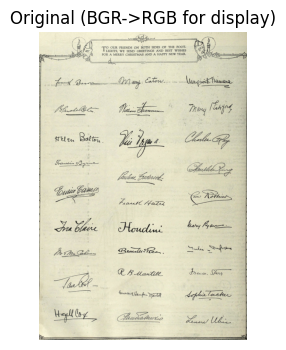

In [30]:
# Set image path (change this to your signature image)
img_path = Path("signatures.jpg")  # <- change if needed
img = cv.imread(str(img_path))
if img is None:
    raise FileNotFoundError(f"Image not found: {img_path.resolve()}")

# Show original
show(img, 'Original (BGR->RGB for display)')

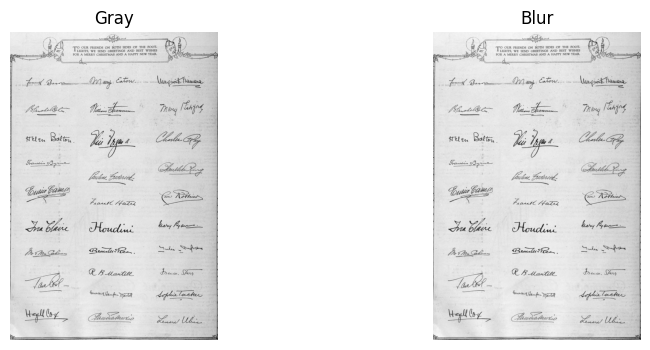

In [31]:
# 1) Convert to gray and blur (reduce noise)
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
# Gaussian blur + optional median blur for salt-and-pepper
blur = cv.GaussianBlur(gray, (5,5), 0)
# blur = cv.medianBlur(blur, 3)

plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.imshow(gray, cmap='gray')
plt.title('Gray')
plt.axis('off')
plt.subplot(1,2,2)
plt.imshow(blur, cmap='gray')
plt.title('Blur')
plt.axis('off')
plt.show()

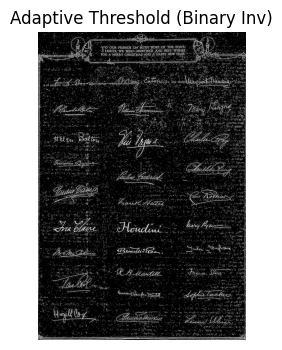

In [32]:
# 2) Adaptive threshold (better for uneven illumination)
# Using THRESH_BINARY_INV so strokes become white on black background
th = cv.adaptiveThreshold(blur, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C,
                       cv.THRESH_BINARY_INV, 11, 2)

plt.figure(figsize=(6,4))
plt.imshow(th, cmap='gray')
plt.title('Adaptive Threshold (Binary Inv)')
plt.axis('off')
plt.show()

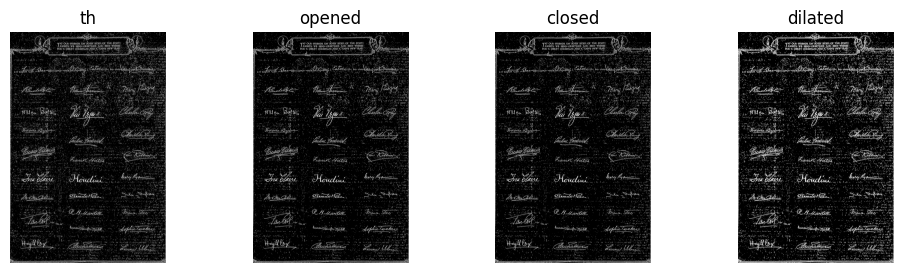

In [33]:
# 3) Morphological operations with an elliptical kernel
kernel = cv.getStructuringElement(cv.MORPH_ELLIPSE, (3,3))
# Opening to remove small noise, then closing to join nearby strokes
opened = cv.morphologyEx(th, cv.MORPH_OPEN, kernel, iterations=1)
closed = cv.morphologyEx(opened, cv.MORPH_CLOSE, kernel, iterations=1)
# Optionally thicken strokes (dilation)
dilated = cv.dilate(closed, kernel, iterations=1)

plt.figure(figsize=(12,3))
plt.subplot(1,4,1); plt.imshow(th, cmap='gray'); plt.title('th'); plt.axis('off')
plt.subplot(1,4,2); plt.imshow(opened, cmap='gray'); plt.title('opened'); plt.axis('off')
plt.subplot(1,4,3); plt.imshow(closed, cmap='gray'); plt.title('closed'); plt.axis('off')
plt.subplot(1,4,4); plt.imshow(dilated, cmap='gray'); plt.title('dilated'); plt.axis('off')
plt.show()

In [34]:
# 4) Find contours and select the largest by area (assumed signature)
contours, _ = cv.findContours(dilated, cv.RETR_EXTERNAL, cv.CHAIN_APPROX_SIMPLE)
if len(contours) == 0:
    raise RuntimeError('No contours found - try adjusting preprocessing parameters')

largest = max(contours, key=cv.contourArea)
x,y,w,h = cv.boundingRect(largest)

# Visualize bounding box on a copy
vis = img.copy()

#cv.rectangle(vis, (x,y), (x+w, y+h), (0,255,0), 2)

croppedImage=I(y:y+h, x:x+w)

show(vis, 'Largest Contour Bounding Box')

# Crop region of interest
cropped = img[y:y+h, x:x+w].copy()
mask_crop = dilated[y:y+h, x:x+w]
# Convert mask_crop to 3-channel to composite if needed
mask3 = cv.cvtColor(mask_crop, cv.COLOR_GRAY2BGR)
# Make background white where mask is background (0)
white_bg = np.ones_like(cropped, dtype=np.uint8) * 255
segmented = np.where(mask3==0, white_bg, cropped)
show(segmented, 'Cropped & Segmented')

SyntaxError: invalid syntax (3101822559.py, line 14)

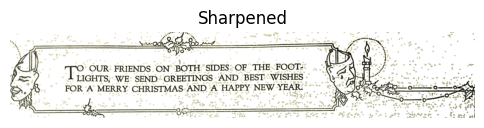

Saved: segmented_signature.png and segmented_signature_sharpened.png


In [35]:
# 5) Sharpen the cropped image (unsharp mask via kernel)
# Convert to BGR already; apply a simple sharpening kernel
kernel_sharp = np.array([[0,-1,0],[-1,5,-1],[0,-1,0]], dtype=np.float32)
sharpened = cv.filter2D(segmented, -1, kernel_sharp)
show(sharpened, 'Sharpened')

# Save outputs
out_dir = Path('.')
cv.imwrite(str(out_dir / 'segmented_signature.png'), segmented)
cv.imwrite(str(out_dir / 'segmented_signature_sharpened.png'), sharpened)
print('Saved: segmented_signature.png and segmented_signature_sharpened.png')

## Notes & Tips
- If the result misses strokes or includes noise, try changing kernel sizes, adaptive threshold blockSize (cell 5) or number of morphology iterations.
- For blue ink signatures you may want to perform a color-space split (e.g., LAB) and threshold the B channel instead of grayscale.
- This pipeline is a simple starting point — additional cleaning (connected components filtering, heuristic area filtering) can improve robustness.

In [ ]:
# croppedImage=I(y:y+h, x:x+w)